<a href="https://colab.research.google.com/github/ajmalyaseen/sms-spam-detection-using-Naive-Bayes/blob/main/sms_spam_detection_naive_bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install opendatasets legacy-cgi

In [4]:
import opendatasets as od

In [5]:
od.download("https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: aj
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset


100%|██████████| 211k/211k [00:00<00:00, 394kB/s]

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [7]:
import pandas as pd

df = pd.read_csv("/content/sms-spam-collection-dataset/spam.csv", encoding="latin-1")

print(df.head())
print(df.shape)
print(df.columns)


     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  
(5572, 5)
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')


In [8]:
df = df[["v1", "v2"]]

# Rename columns
df.columns = ["label", "message"]

print(df.head())
print(df.shape)
print(df.isnull().sum())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
(5572, 2)
label      0
message    0
dtype: int64


In [9]:
print("Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["label"].value_counts())

Shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403

Target distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [10]:
print(df[df.duplicated()].head(10))

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print(df["label"].value_counts())

    label                                            message
102   ham  As per your request 'Melle Melle (Oru Minnamin...
153   ham  As per your request 'Melle Melle (Oru Minnamin...
206   ham  As I entered my cabin my PA said, '' Happy B'd...
222   ham                             Sorry, I'll call later
325   ham                   No calls..messages..missed calls
338   ham                             Sorry, I'll call later
356  spam  Congratulations ur awarded 500 of CD vouchers ...
443   ham                             Sorry, I'll call later
532   ham                  Gudnite....tc...practice going on
654   ham                       Did u got that persons story
Shape after removing duplicates: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64


In [11]:
df.duplicated().sum()

np.int64(0)

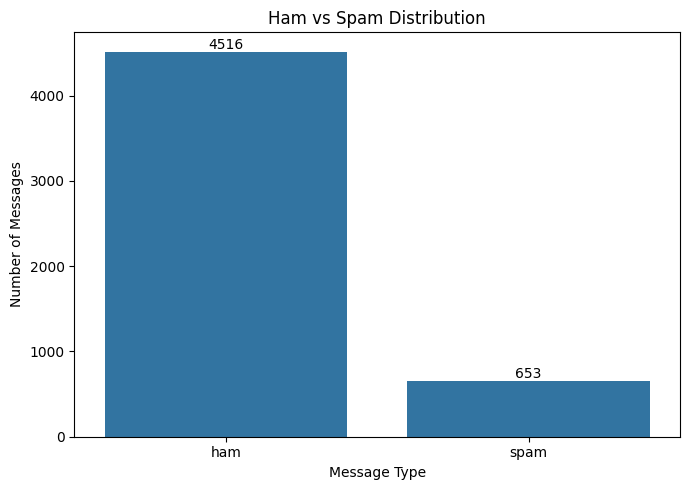

label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="label")

plt.title("Ham vs Spam Distribution")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

print((df["label"].value_counts(normalize=True) * 100).round(2))


        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4516.0   70.459256  56.358207   2.0   34.0   52.0   90.0  910.0
spam    653.0  137.891271  30.137753  13.0  132.0  149.0  157.0  224.0


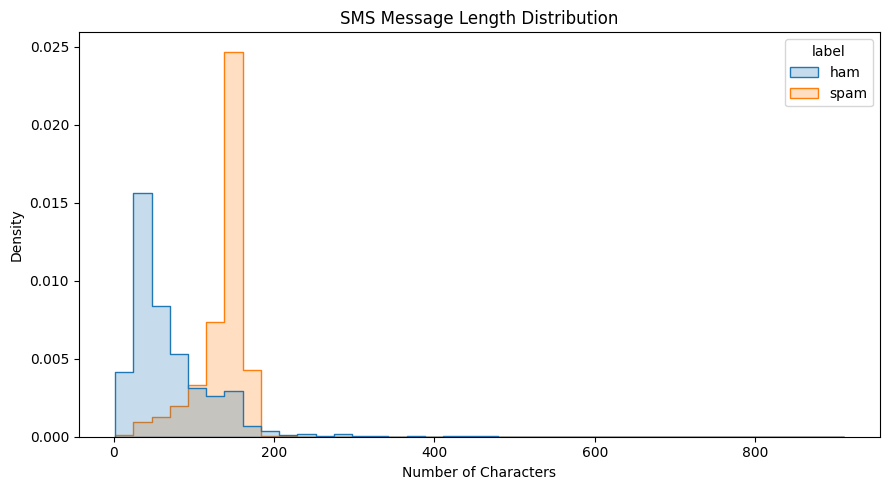

In [13]:
df["message_length"] = df["message"].str.len()

print(df.groupby("label")["message_length"].describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("SMS Message Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import train_test_split

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 4135
Testing samples: 1034

Training distribution:
label
ham     3613
spam     522
Name: count, dtype: int64

Testing distribution:
label
ham     903
spam    131
Name: count, dtype: int64


#BASE LINE MODEL

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("nb", MultinomialNB())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Baseline model trained successfully!")
print("Predictions:", y_pred[:20])

Baseline model trained successfully!
Predictions: ['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [16]:
print(y_test[:20])

4940    ham
4908    ham
2358    ham
1267    ham
4738    ham
666     ham
4182    ham
5115    ham
4614    ham
4460    ham
1145    ham
2760    ham
2146    ham
3607    ham
1590    ham
3226    ham
4071    ham
81      ham
2298    ham
3950    ham
Name: label, dtype: object


Accuracy: 0.9516441005802708

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.62      0.76       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.95      0.95      0.95      1034



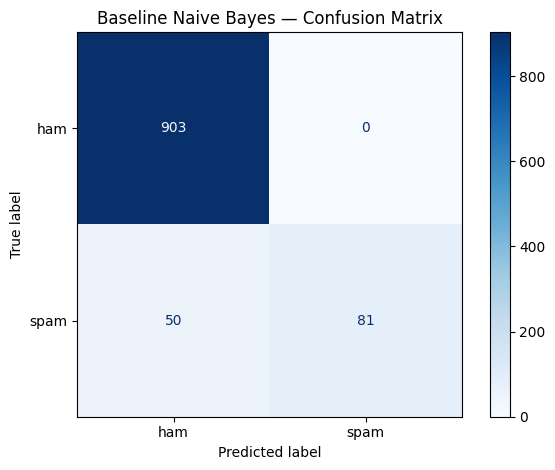

In [17]:
#evaluation of baseline model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Baseline Naive Bayes — Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
results = pd.DataFrame({
    "message": X_test,
    "actual": y_test,
    "predicted": y_pred
})

false_negatives = results[
    (results["actual"] == "spam") &
    (results["predicted"] == "ham")
]

print("Missed spam messages:", len(false_negatives))
print(false_negatives["message"].head(10))

Missed spam messages: 50
3383    I am hot n horny and willing I live local to y...
1458    Thanks for the Vote. Now sing along with the s...
5137    Want explicit SEX in 30 secs? Ring 02073162414...
520     You will recieve your tone within the next 24h...
2695    Send a logo 2 ur lover - 2 names joined by a h...
483     Congrats! 1 year special cinema pass for 2 is ...
2906    Hi babe its Jordan, how r u? Im home from abro...
1610    Hi if ur lookin 4 saucy daytime fun wiv busty ...
4752    TheMob>Hit the link to get a premium Pink Pant...
1404    As a registered optin subscriber ur draw 4 å£1...
Name: message, dtype: object


In [19]:
for i, message in enumerate(false_negatives["message"].head(10), start=1):
    print(f"\nMessage {i}:\n{message}")


Message 1:
I am hot n horny and willing I live local to you - text a reply to hear strt back from me 150p per msg Netcollex LtdHelpDesk: 02085076972 reply Stop to end

Message 2:
Thanks for the Vote. Now sing along with the stars with Karaoke on your mobile. For a FREE link just reply with SING now.

Message 3:
Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min Gsex POBOX 2667 WC1N 3XX

Message 4:
You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750

Message 5:
Send a logo 2 ur lover - 2 names joined by a heart. Txt LOVE NAME1 NAME2 MOBNO eg LOVE ADAM EVE 07123456789 to 87077 Yahoo! POBox36504W45WQ TxtNO 4 no ads 150p.

Message 6:
Congrats! 1 year special cinema pass for 2 is yours. call 09061209465 now! C Suprman V, Matrix3, StarWars3, etc all 4 FREE! bx420-ip4-5we. 150pm. Dont miss out!

Message 7:
Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text

In [20]:
diagnostics = results.loc[false_negatives.index].copy()
diagnostics["message_length"] = diagnostics["message"].str.len()

In [21]:
spam_index = list(model.classes_).index("spam")
spam_index

1

In [22]:
diagnostics["spam_probability"] = model.predict_proba(
    diagnostics["message"]
)[:, spam_index]

In [23]:
diagnostics

,message,actual,predicted,message_length,spam_probability
3383,I am hot n horny and willing I live local to y...,spam,ham,155,0.425350
1458,Thanks for the Vote. Now sing along with the s...,spam,ham,121,0.150728
5137,Want explicit SEX in 30 secs? Ring 02073162414...,spam,ham,90,0.278064
520,You will recieve your tone within the next 24h...,spam,ham,111,0.261625
2695,Send a logo 2 ur lover - 2 names joined by a h...,spam,ham,160,0.245155
483,Congrats! 1 year special cinema pass for 2 is ...,spam,ham,160,0.332359
2906,"Hi babe its Jordan, how r u? Im home from abro...",spam,ham,147,0.046665
1610,Hi if ur lookin 4 saucy daytime fun wiv busty ...,spam,ham,160,0.079408
4752,TheMob>Hit the link to get a premium Pink Pant...,spam,ham,149,0.212052
1404,As a registered optin subscriber ur draw 4 å£1...,spam,ham,142,0.448154


In [24]:
for _, row in diagnostics.head(10).iterrows():
    print("-" * 70)
    print("Message:", row["message"])
    print("Length:", row["message_length"])
    print("Spam probability:", round(row["spam_probability"], 4))
    print("Prediction:", row["predicted"])

----------------------------------------------------------------------
Message: I am hot n horny and willing I live local to you - text a reply to hear strt back from me 150p per msg Netcollex LtdHelpDesk: 02085076972 reply Stop to end
Length: 155
Spam probability: 0.4254
Prediction: ham
----------------------------------------------------------------------
Message: Thanks for the Vote. Now sing along with the stars with Karaoke on your mobile. For a FREE link just reply with SING now.
Length: 121
Spam probability: 0.1507
Prediction: ham
----------------------------------------------------------------------
Message: Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min Gsex POBOX 2667 WC1N 3XX
Length: 90
Spam probability: 0.2781
Prediction: ham
----------------------------------------------------------------------
Message: You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750
Length: 111
Spam probability: 0.2616
Pred

In [28]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer,recall_score

In [31]:
spam_recall=make_scorer(recall_score,pos_label="spam")
param_grid={"nb__alpha":[0.01,0.1,1,10,100]}
search=GridSearchCV(estimator=model,
             param_grid=param_grid,
             cv=5,
             scoring=spam_recall,
             n_jobs=-1
             )

In [32]:
#training the model using hyper parametrs
search.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('tfidf', TfidfVectorizer()),
                                       ('nb', MultinomialNB())]),
             n_jobs=-1, param_grid={'nb__alpha': [0.01, 0.1, 1, 10, 100]},
             scoring=make_scorer(recall_score, response_method='predict', pos_label=spam))

In [33]:
search.best_params_

{'nb__alpha': 0.01}

In [34]:
search.best_score_

np.float64(0.9041391941391941)

In [35]:
best_model=search.best_estimator_

In [36]:
y_pred_tuned=best_model.predict(X_test)

In [37]:
print(y_pred_tuned)

['ham' 'ham' 'ham' ... 'spam' 'ham' 'ham']


In [38]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.97      0.89      0.93       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



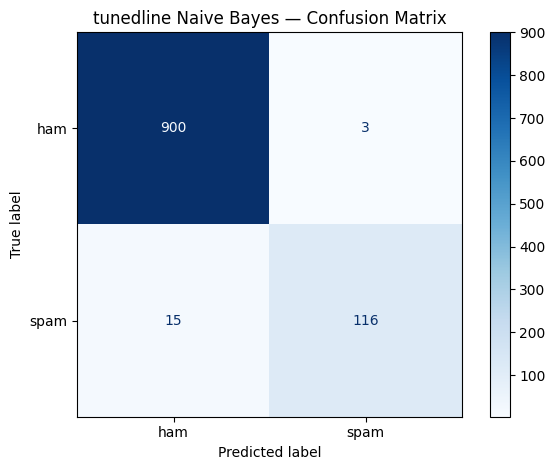

In [39]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    cmap="Blues"
)

plt.title("Tuned Naive Bayes — Confusion Matrix")
plt.tight_layout()
plt.show()

In [40]:
def predict_sms(message):
    pred = best_model.predict([message])[0]

    probabilities = best_model.predict_proba([message])[0]

    class_labels = best_model.classes_
    confidence = dict(zip(class_labels, probabilities))

    return {
        "message": message,
        "prediction": pred,
        "confidence": round(confidence[pred] * 100, 2),
        "ham_probability": round(confidence["ham"] * 100, 2),
        "spam_probability": round(confidence["spam"] * 100, 2)
    }

In [49]:
while True:
  sms=input("""enetr your sms: """)
  if sms=="exit":
    break
  print()
  pred=predict_sms(sms)

  for key,value in pred.items():
    print(key,":",value)
  print("------------------------------")

enetr your sms: SuperHero 979=Half Day Unlimited Data (12 AM-12PM) +2GB/D,84 days 1)179:UL+1GB,28D,  2)250:UL Calls+2GB+0.5GB/D+Spotify,28D viapp.onelink.me/bSC3/121

message : SuperHero 979=Half Day Unlimited Data (12 AM-12PM) +2GB/D,84 days 1)179:UL+1GB,28D,  2)250:UL Calls+2GB+0.5GB/D+Spotify,28D viapp.onelink.me/bSC3/121
prediction : spam
confidence : 98.08
ham_probability : 1.92
spam_probability : 98.08
------------------------------
enetr your sms: Dear Customer, You have a missed call from +918089041432 The last missed call was at 12:39 PM on 17-Aug-2026 Thankyou, Team Jio.

message : Dear Customer, You have a missed call from +918089041432 The last missed call was at 12:39 PM on 17-Aug-2026 Thankyou, Team Jio.
prediction : ham
confidence : 89.3
ham_probability : 89.3
spam_probability : 10.7
------------------------------
enetr your sms: exit
